# Analisis dan Prediksi Kategori Sleep Debt

Notebook ini membandingkan Ordinal Logistic Regression dan Decision Tree Classification untuk memprediksi `sleep_debt_category`. Dataset: `bedtime_screentime_sleep_debt.csv`. Fitur yang berpotensi membocorkan informasi hasil tidur atau target dikeluarkan. Analisis ini tidak menguji hubungan sebab-akibat dan tidak mencakup Ablation Study.

**Urutan target:** Optimal Recovery < Mild Deficit < Moderate Debt < Severe Sleep Debt.

**Reproducibility:** pembagian data menggunakan `random_state = 42` dan stratifikasi target. Preprocessing di-fit hanya pada data training.


## 1. Import library
Memuat pustaka untuk pengolahan data, preprocessing, pemisahan data, dua model, dan evaluasi.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.miscmodels.ordinal_model import OrderedModel

RANDOM_STATE = 42
TARGET = "sleep_debt_category"
CLASS_ORDER = [
    "Optimal Recovery",
    "Mild Deficit",
    "Moderate Debt",
    "Severe Sleep Debt",
]


## 2. Load dataset
Membaca file CSV yang berada satu folder dengan notebook dan menampilkan bentuk serta contoh data secara terbatas.

In [2]:
DATA_PATH = Path("bedtime_screentime_sleep_debt.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File {DATA_PATH} tidak ditemukan. Simpan CSV satu folder dengan notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Ukuran dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom")
display(df.head())
display(df.dtypes.rename("tipe_data").to_frame())


Ukuran dataset: 8,500 baris x 18 kolom


     user_id  age      gender            occupation_type    chronotype  bedtime_phone_minutes primary_bedtime_app  screen_brightness_pct  blue_light_filter_active  caffeine_post_5pm_mg  physical_activity_min  sleep_latency_min  total_sleep_hours  deep_sleep_pct  rem_sleep_pct  morning_alarm_snoozes  next_day_fatigue_score sleep_debt_category
0  USR-00001   29      Female  Healthcare / Shift Worker  Intermediate                    179  Instagram / Reddit                     54                         1                     0                     21               84.4               3.20            23.5           22.2                      7                    10.0   Severe Sleep Debt
1  USR-00002   58      Female                    Student  Intermediate                    163             YouTube                     76                         1                    92                     72               86.7               4.06            18.0           21.5                      7             

                         tipe_data
user_id                        str
age                          int64
gender                         str
occupation_type                str
chronotype                     str
bedtime_phone_minutes        int64
primary_bedtime_app            str
screen_brightness_pct        int64
blue_light_filter_active     int64
caffeine_post_5pm_mg         int64
physical_activity_min        int64
sleep_latency_min          float64
total_sleep_hours          float64
deep_sleep_pct             float64
rem_sleep_pct              float64
morning_alarm_snoozes        int64
next_day_fatigue_score     float64
sleep_debt_category            str

## 3. Data cleaning
Membersihkan spasi pada teks, mengubah string kosong menjadi missing value, menghapus duplikasi persis, dan membuang baris tanpa target. Missing pada fitur akan ditangani di pipeline yang di-fit pada data training.

In [3]:
df = df.replace(r"^\s*$", np.nan, regex=True)
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

rows_before = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = rows_before - len(df)
missing_target = int(df[TARGET].isna().sum())
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(str).str.strip()

unknown_labels = sorted(set(df[TARGET].unique()) - set(CLASS_ORDER))
if unknown_labels:
    raise ValueError(f"Kategori target di luar definisi: {unknown_labels}")

print(f"Duplikasi persis dihapus: {duplicates_removed}")
print(f"Baris tanpa target dihapus: {missing_target}")
print(f"Ukuran setelah cleaning: {df.shape[0]:,} baris x {df.shape[1]} kolom")
display(df.isna().sum().rename("jumlah_missing").to_frame())


Duplikasi persis dihapus: 0
Baris tanpa target dihapus: 0
Ukuran setelah cleaning: 8,500 baris x 18 kolom


                          jumlah_missing
user_id                                0
age                                    0
gender                                 0
occupation_type                        0
chronotype                             0
bedtime_phone_minutes                  0
primary_bedtime_app                    0
screen_brightness_pct                  0
blue_light_filter_active               0
caffeine_post_5pm_mg                   0
physical_activity_min                  0
sleep_latency_min                      0
total_sleep_hours                      0
deep_sleep_pct                         0
rem_sleep_pct                          0
morning_alarm_snoozes                  0
next_day_fatigue_score                 0
sleep_debt_category                    0

## 4. Feature engineering dan encoding target
Target dipetakan ke kode berurutan sesuai tingkat sleep debt. Encoding fitur kategorikal dilakukan oleh `OneHotEncoder` di dalam preprocessing setelah data dibagi, bukan sebelum split.

In [4]:
df[TARGET] = pd.Categorical(
    df[TARGET], categories=CLASS_ORDER, ordered=True
)
df["target_code"] = df[TARGET].cat.codes
if (df["target_code"] < 0).any():
    raise ValueError("Ada target yang tidak berhasil dikodekan.")

class_distribution = (
    df[TARGET].value_counts(sort=False)
    .rename_axis(TARGET)
    .to_frame("jumlah")
)
class_distribution["proporsi"] = class_distribution["jumlah"] / len(df)
display(class_distribution)


                     jumlah  proporsi
sleep_debt_category                  
Optimal Recovery       1387  0.163176
Mild Deficit           2004  0.235765
Moderate Debt          4462  0.524941
Severe Sleep Debt       647  0.076118

## 5. Pemilihan fitur dan pencegahan data leakage
`user_id` dikeluarkan karena hanya identifier. `total_sleep_hours`, indikator kualitas/latensi tidur, snooze alarm, dan kelelahan hari berikutnya dikeluarkan karena berisiko menjadi dasar, hasil, atau proksi langsung kategori target. Prediktor yang tersisa mewakili karakteristik individu dan kebiasaan yang tercatat.

In [5]:
LEAKAGE_OR_ID_COLUMNS = [
    "user_id",
    "total_sleep_hours",
    "sleep_latency_min",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes",
    "next_day_fatigue_score",
    TARGET,
    "target_code",
]
feature_columns = [c for c in df.columns if c not in LEAKAGE_OR_ID_COLUMNS]

if not feature_columns:
    raise ValueError("Tidak ada fitur tersisa setelah pemeriksaan leakage.")
X = df[feature_columns].copy()
y = df["target_code"].astype(int).copy()

categorical_features = [
    c for c in [
        "gender", "occupation_type", "chronotype",
        "primary_bedtime_app", "blue_light_filter_active"
    ] if c in X.columns
]
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Fitur digunakan:", feature_columns)
print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)


Fitur digunakan: ['age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min']
Fitur numerik: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg', 'physical_activity_min']
Fitur kategorikal: ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'blue_light_filter_active']


## 6. Pembagian training dan testing serta preprocessing
Data dibagi satu kali dengan proporsi test 20%, stratifikasi target, dan seed 42. Imputasi, scaling numerik, serta one-hot encoding di-fit hanya pada `X_train`; transformasi yang sama diterapkan ke test set.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)),
])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=0.0,
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print(f"Training: {len(X_train):,} baris | Testing: {len(X_test):,} baris")
print(f"Jumlah fitur setelah encoding: {X_train_processed.shape[1]}")


Training: 6,800 baris | Testing: 1,700 baris
Jumlah fitur setelah encoding: 19


## 7. Implementasi Ordinal Logistic Regression
Model proportional-odds menggunakan distribusi logit. Target mempertahankan urutan kategori. Matriks fitur tidak ditambah konstanta karena `OrderedModel` mengestimasi threshold kategori; fitur preprocessing hanya di-fit menggunakan training set.

In [7]:
y_train_ordinal = pd.Series(
    pd.Categorical.from_codes(
        y_train.to_numpy(), categories=CLASS_ORDER, ordered=True
    ),
    index=y_train.index,
)
ordinal_model = OrderedModel(
    endog=y_train_ordinal,
    exog=X_train_processed,
    distr="logit",
)


## 8. Implementasi Decision Tree Classification
Decision Tree memprediksi empat kelas target. Seed yang sama dipakai untuk menjaga hasil proses model dapat direproduksi; parameter kedalaman dibiarkan default agar tahap ini menjadi implementasi dasar.

In [8]:
tree_model = DecisionTreeClassifier(random_state=RANDOM_STATE)


## 9. Pelatihan dan prediksi kedua model
Kedua model dilatih menggunakan training set yang sama dan matriks hasil preprocessing yang sama. Prediksi Ordinal Logistic Regression dipilih dari probabilitas kelas tertinggi.

In [9]:
with warnings.catch_warnings():
    warnings.simplefilter("default")
    ordinal_result = ordinal_model.fit(method="bfgs", maxiter=500, disp=False)

tree_model.fit(X_train_processed, y_train)

ordinal_probabilities = np.asarray(
    ordinal_result.model.predict(ordinal_result.params, exog=X_test_processed)
)
y_pred_ordinal = ordinal_probabilities.argmax(axis=1)
y_pred_tree = tree_model.predict(X_test_processed)

print("Pelatihan selesai.")
print("Jumlah prediksi test set:", len(y_test))


Pelatihan selesai.
Jumlah prediksi test set: 1700


## 10. Evaluasi: metrik dan confusion matrix
Accuracy menunjukkan proporsi prediksi benar. Precision, Recall, dan F1 dihitung secara macro agar setiap kelas mendapat bobot yang sama, termasuk kelas minoritas. Confusion matrix memakai urutan kelas target yang telah ditetapkan.

                              Accuracy  Precision (Macro)  Recall (Macro)  Macro-F1
Model                                                                              
Ordinal Logistic Regression     0.7212             0.7015          0.6401    0.6652
Decision Tree Classification    0.6359             0.5872          0.5873    0.5866

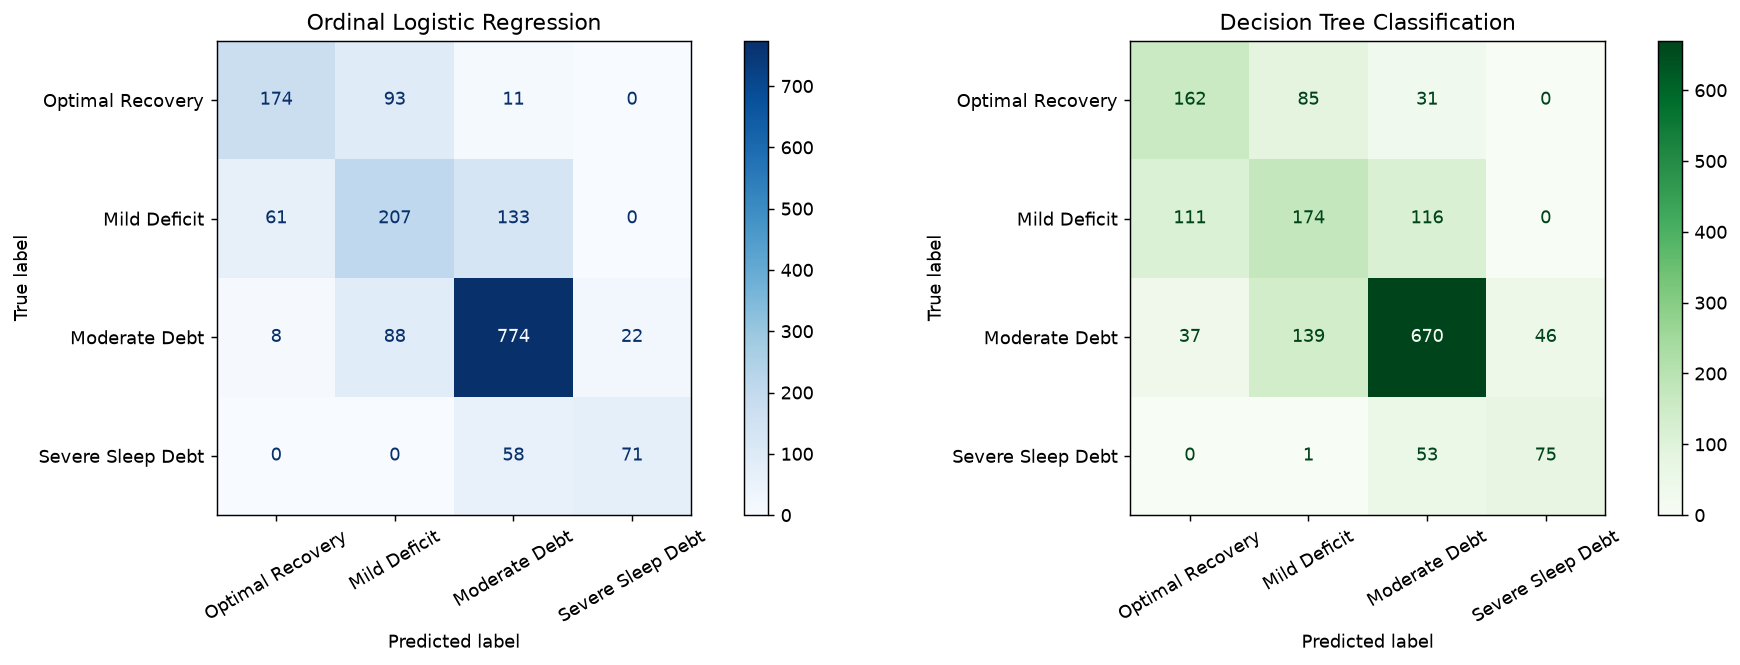

In [10]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }

metrics = pd.DataFrame([
    evaluate_model("Ordinal Logistic Regression", y_test, y_pred_ordinal),
    evaluate_model("Decision Tree Classification", y_test, y_pred_tree),
]).set_index("Model")
display(metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_ordinal, labels=np.arange(len(CLASS_ORDER)),
    display_labels=CLASS_ORDER, values_format="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("Ordinal Logistic Regression")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tree, labels=np.arange(len(CLASS_ORDER)),
    display_labels=CLASS_ORDER, values_format="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("Decision Tree Classification")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.show()


## 11. Perbandingan performa kedua model
Tabel dan grafik berikut merangkum metrik evaluasi dari test set yang sama. Interpretasi hasil perlu mempertimbangkan ketidakseimbangan kelas dan bahwa evaluasi ini mengukur prediksi kategori, bukan hubungan sebab-akibat.

                              Accuracy  Precision (Macro)  Recall (Macro)  Macro-F1
Model                                                                              
Ordinal Logistic Regression     0.7212             0.7015          0.6401    0.6652
Decision Tree Classification    0.6359             0.5872          0.5873    0.5866

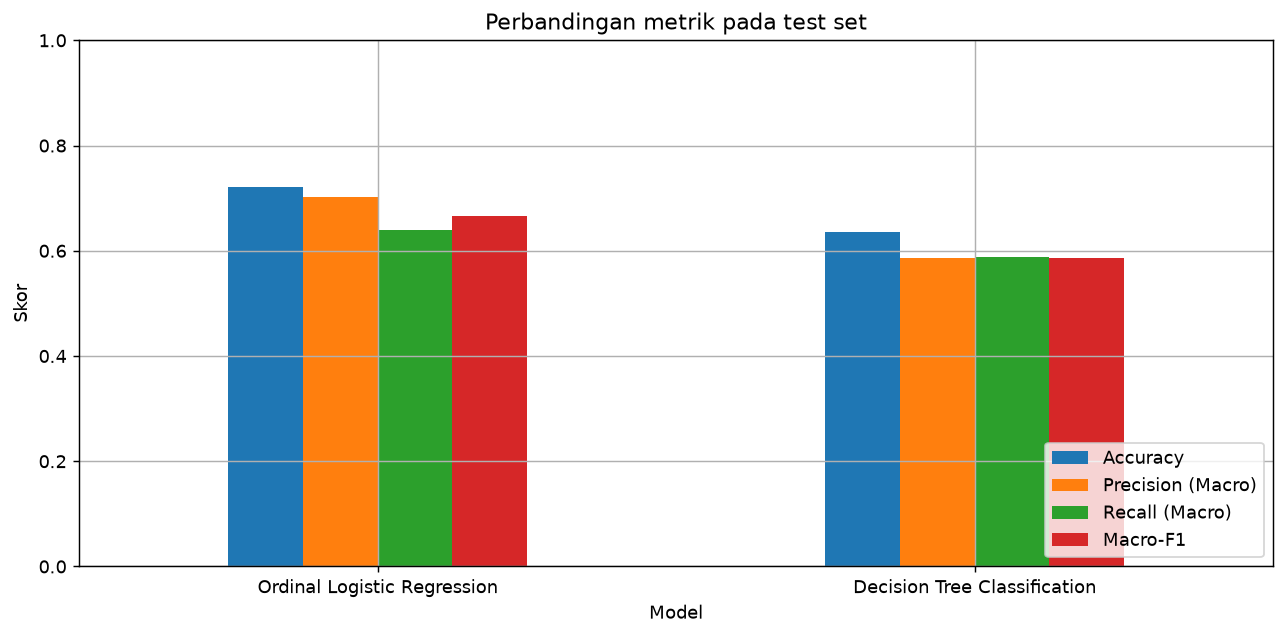

In [11]:
display(metrics.round(4))
ax = metrics.plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1),
    ylabel="Skor", title="Perbandingan metrik pada test set",
    rot=0, grid=True,
)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 12. Rancangan Ablation Study

Ablation mengukur perubahan performa ketika satu fitur atau kelompok fitur dihapus dari model yang sama. Baseline untuk setiap algoritma memakai seluruh 10 prediktor valid. Setiap skenario memakai split training/testing yang sama, preprocessing yang di-fit hanya pada training set, dan konfigurasi model yang sama dengan evaluasi sebelumnya. Perbandingan Ordinal Logistic Regression dengan Decision Tree bukan ablation; dampak ablation dinilai di dalam masing-masing model.

| Skenario | Fitur yang dihapus | Tujuan dan alasan | Indikator evaluasi |
|---|---|---|---|
| Baseline | Tidak ada | Acuan performa dengan seluruh fitur valid. | Accuracy dan Macro-F1. |
| Tanpa screen time | `bedtime_phone_minutes` | Mengukur kontribusi tambahan durasi penggunaan smartphone malam hari, fitur utama penelitian. | Perubahan Accuracy dan Macro-F1 terhadap baseline model yang sama. |
| Tanpa chronotype | `chronotype` | Mengukur kontribusi karakteristik kecenderungan waktu tidur individu. | Perubahan Accuracy dan Macro-F1 terhadap baseline model yang sama. |
| Tanpa konsumsi kafein | `caffeine_post_5pm_mg` | Mengukur kontribusi informasi konsumsi kafein setelah pukul 17.00. | Perubahan Accuracy dan Macro-F1 terhadap baseline model yang sama. |
| Tanpa aktivitas fisik | `physical_activity_min` | Mengukur kontribusi informasi durasi aktivitas fisik. | Perubahan Accuracy dan Macro-F1 terhadap baseline model yang sama. |
| Tanpa kelompok fitur penggunaan smartphone | `bedtime_phone_minutes`, `primary_bedtime_app`, `screen_brightness_pct`, `blue_light_filter_active` | Mengukur kontribusi gabungan perilaku dan pengaturan penggunaan smartphone pada malam hari. | Perubahan Accuracy dan Macro-F1 terhadap baseline model yang sama. |

Penurunan skor didefinisikan sebagai `skor baseline - skor skenario` dalam poin persentase. Nilai positif berarti skor menurun setelah fitur dihapus; nilai negatif berarti skor justru meningkat. Macro-F1 menjadi indikator penting karena distribusi kelas tidak seimbang, sedangkan Accuracy tetap dicatat untuk menunjukkan ketepatan keseluruhan. Hasil menunjukkan kontribusi prediktif pada dataset ini, bukan sebab-akibat.


### 12.1 Definisi skenario dan preprocessing konsisten
Helper berikut membangun ulang preprocessing untuk setiap subset fitur. Imputer, scaler, dan encoder di-fit hanya pada data training dari split Tahap 3 yang sama.

In [12]:
ABLATION_SCENARIOS = {
    "Baseline - seluruh fitur valid": [],
    "Tanpa bedtime_phone_minutes": ["bedtime_phone_minutes"],
    "Tanpa chronotype": ["chronotype"],
    "Tanpa caffeine_post_5pm_mg": ["caffeine_post_5pm_mg"],
    "Tanpa physical_activity_min": ["physical_activity_min"],
    "Tanpa kelompok fitur smartphone": [
        "bedtime_phone_minutes",
        "primary_bedtime_app",
        "screen_brightness_pct",
        "blue_light_filter_active",
    ],
}

def make_ablation_preprocessor(selected_features):
    numeric = [c for c in selected_features if c in numeric_features]
    categorical = [c for c in selected_features if c in categorical_features]
    return ColumnTransformer(
        transformers=[
            ("numeric", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric),
            ("categorical", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore", drop="first", sparse_output=False
                )),
            ]), categorical),
        ],
        remainder="drop",
        sparse_threshold=0.0,
    )

print(f"Skenario termasuk baseline: {len(ABLATION_SCENARIOS)}")
print(f"Fitur valid pada baseline: {len(feature_columns)}")


Skenario termasuk baseline: 6
Fitur valid pada baseline: 10


### 12.2 Jalankan setiap skenario pada kedua model
Untuk tiap skenario, kedua model dilatih ulang dari awal pada fitur yang tersisa. Skor dihitung pada test set yang sama.

In [13]:
ablation_records = []

for scenario_name, removed_features in ABLATION_SCENARIOS.items():
    selected_features = [
        feature for feature in feature_columns
        if feature not in removed_features
    ]
    if not selected_features:
        raise ValueError(f"Skenario {scenario_name} tidak menyisakan fitur.")

    scenario_preprocessor = make_ablation_preprocessor(selected_features)
    scenario_X_train = scenario_preprocessor.fit_transform(X_train[selected_features])
    scenario_X_test = scenario_preprocessor.transform(X_test[selected_features])

    scenario_ordinal = OrderedModel(
        endog=y_train_ordinal,
        exog=scenario_X_train,
        distr="logit",
    ).fit(method="bfgs", maxiter=500, disp=False)
    scenario_ordinal_probabilities = np.asarray(
        scenario_ordinal.model.predict(
            scenario_ordinal.params, exog=scenario_X_test
        )
    )
    scenario_ordinal_prediction = scenario_ordinal_probabilities.argmax(axis=1)

    scenario_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
    scenario_tree.fit(scenario_X_train, y_train)
    scenario_tree_prediction = scenario_tree.predict(scenario_X_test)

    for model_name, prediction in [
        ("Ordinal Logistic Regression", scenario_ordinal_prediction),
        ("Decision Tree Classification", scenario_tree_prediction),
    ]:
        ablation_records.append({
            "Skenario": scenario_name,
            "Model": model_name,
            "Fitur dihapus": ", ".join(removed_features) if removed_features else "-",
            "Jumlah fitur tersisa": len(selected_features),
            "Accuracy": accuracy_score(y_test, prediction),
            "Macro-F1": f1_score(
                y_test, prediction, average="macro", zero_division=0
            ),
        })

ablation_results = pd.DataFrame(ablation_records)
print("Seluruh skenario selesai.")


Seluruh skenario selesai.


### 12.3 Tabel hasil dan perubahan dari baseline
Tabel mencatat Accuracy dan Macro-F1 untuk setiap model dan skenario. Kolom penurunan menyatakan selisih baseline dikurangi skor skenario, dalam poin persentase.

In [14]:
baseline_scores = (
    ablation_results[
        ablation_results["Skenario"] == "Baseline - seluruh fitur valid"
    ]
    .set_index("Model")[["Accuracy", "Macro-F1"]]
)

ablation_results["Penurunan Accuracy (pp)"] = ablation_results.apply(
    lambda row: (
        baseline_scores.loc[row["Model"], "Accuracy"] - row["Accuracy"]
    ) * 100,
    axis=1,
)
ablation_results["Penurunan Macro-F1 (pp)"] = ablation_results.apply(
    lambda row: (
        baseline_scores.loc[row["Model"], "Macro-F1"] - row["Macro-F1"]
    ) * 100,
    axis=1,
)

display(ablation_results.round({
    "Accuracy": 4,
    "Macro-F1": 4,
    "Penurunan Accuracy (pp)": 2,
    "Penurunan Macro-F1 (pp)": 2,
}))


                           Skenario                         Model                                                                                Fitur dihapus  Jumlah fitur tersisa  Accuracy  Macro-F1  Penurunan Accuracy (pp)  Penurunan Macro-F1 (pp)
0    Baseline - seluruh fitur valid   Ordinal Logistic Regression                                                                                            -                    10    0.7212    0.6652                     0.00                     0.00
1    Baseline - seluruh fitur valid  Decision Tree Classification                                                                                            -                    10    0.6359    0.5866                     0.00                     0.00
2       Tanpa bedtime_phone_minutes   Ordinal Logistic Regression                                                                        bedtime_phone_minutes                     9    0.5859    0.3935                    13.53                    27

### 12.4 Grafik perbandingan baseline dan skenario
Grafik memperlihatkan Accuracy dan Macro-F1 untuk baseline serta semua skenario penghapusan fitur. Perbandingan kontribusi dilakukan antara baseline dan skenario dalam model yang sama.

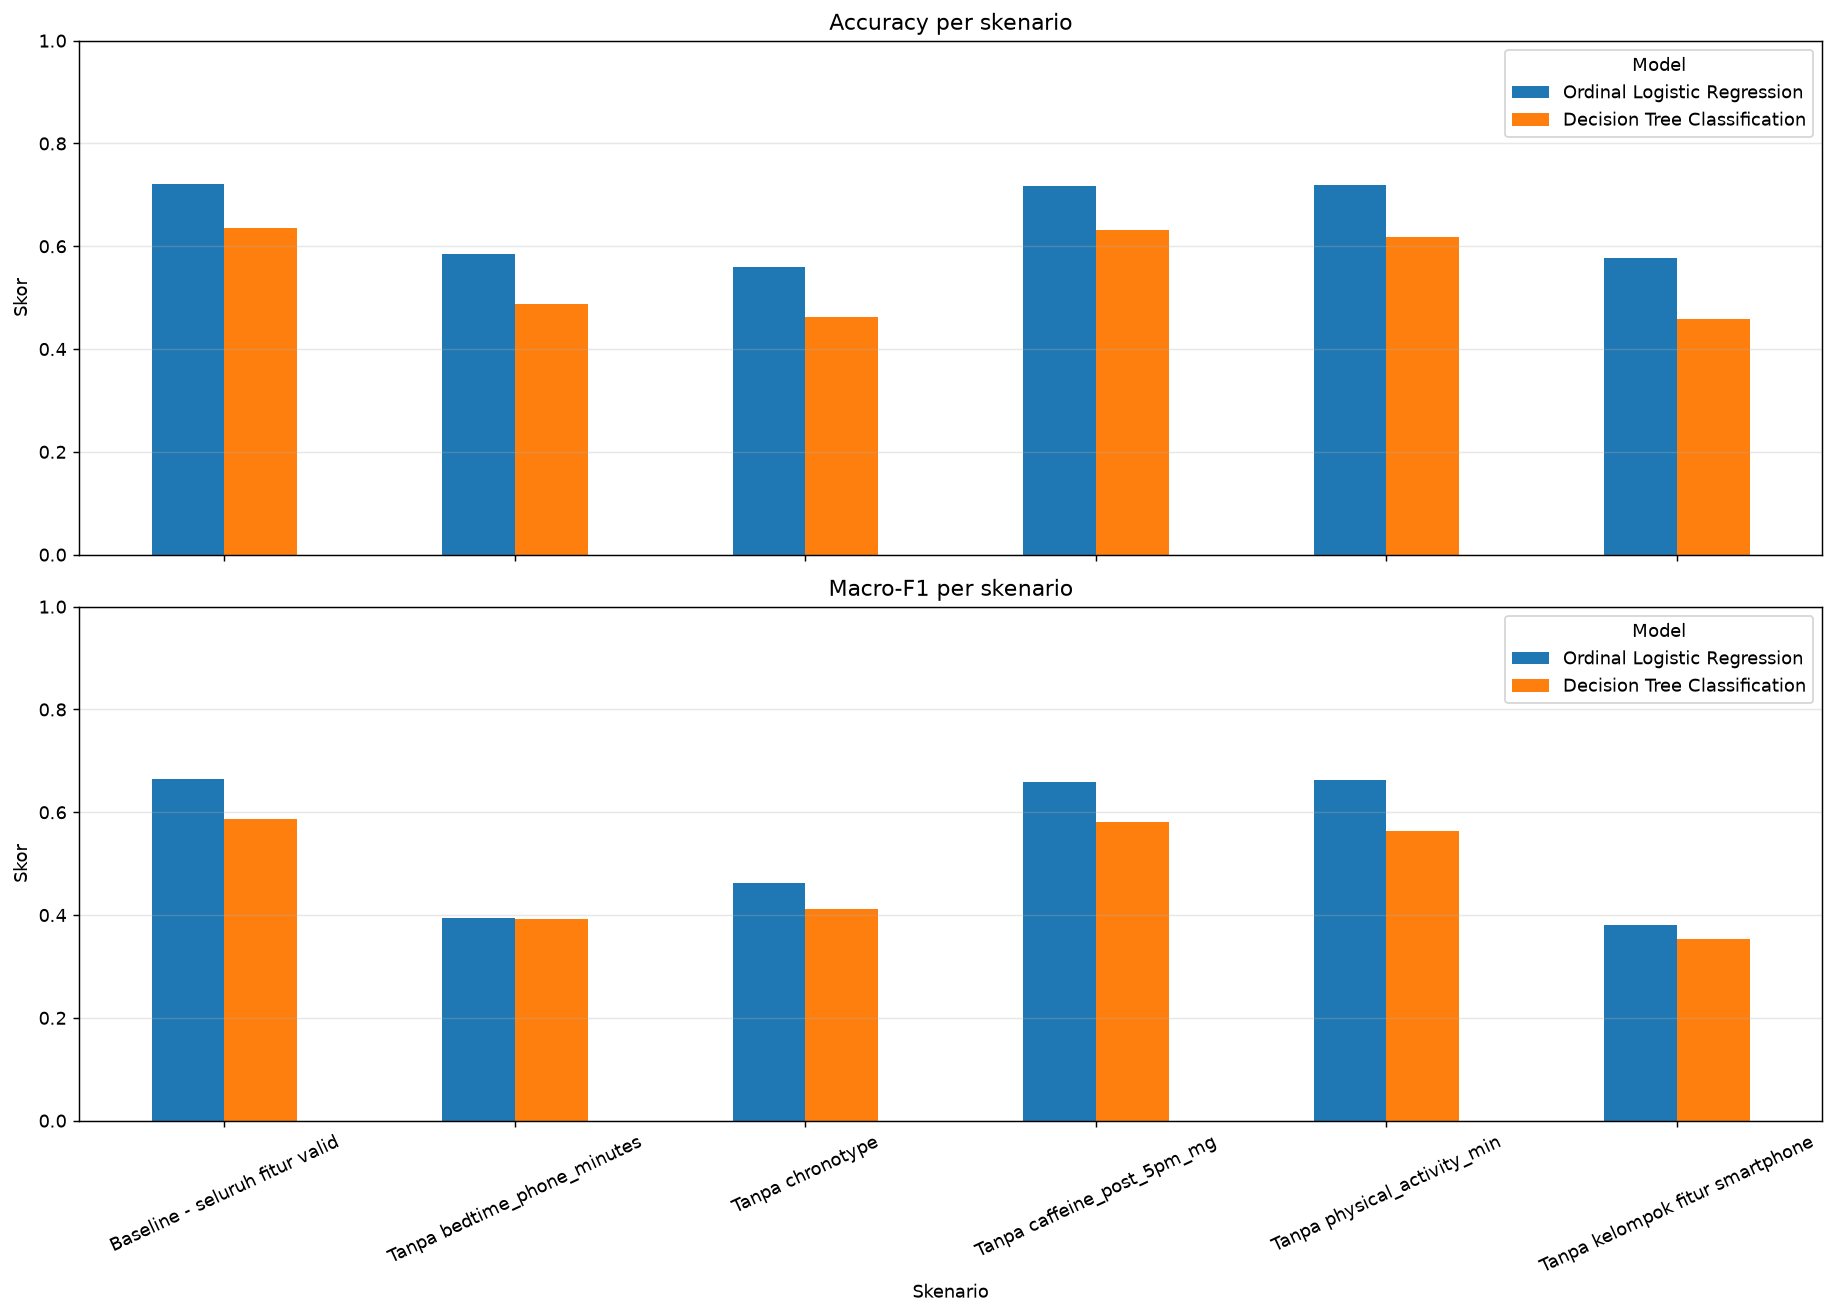

In [15]:
scenario_order = list(ABLATION_SCENARIOS)
model_order = ["Ordinal Logistic Regression", "Decision Tree Classification"]
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True, constrained_layout=True)

for ax, metric, title in [
    (axes[0], "Accuracy", "Accuracy per skenario"),
    (axes[1], "Macro-F1", "Macro-F1 per skenario"),
]:
    pivot = ablation_results.pivot(
        index="Skenario", columns="Model", values=metric
    ).reindex(scenario_order)
    pivot = pivot.reindex(columns=model_order)
    pivot.plot(kind="bar", ax=ax, ylim=(0, 1), rot=25)
    ax.set_title(title)
    ax.set_ylabel("Skor")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Model")

axes[-1].set_xlabel("Skenario")
plt.show()


### 12.5 Analisis fitur dengan dampak terbesar
Skenario dengan penurunan Macro-F1 terbesar menunjukkan fitur/kelompok fitur yang paling banyak menyumbang kemampuan prediksi pada model tersebut. Jika semua penurunan bernilai nol atau negatif, tidak ada penghapusan fitur yang menurunkan Macro-F1 pada eksperimen ini.

In [16]:
ablation_only = ablation_results[
    ablation_results["Skenario"] != "Baseline - seluruh fitur valid"
].copy()

single_feature_names = [
    "Tanpa bedtime_phone_minutes",
    "Tanpa chronotype",
    "Tanpa caffeine_post_5pm_mg",
    "Tanpa physical_activity_min",
]

for model_name in model_order:
    model_scenarios = ablation_only[ablation_only["Model"] == model_name]
    largest_overall = model_scenarios.loc[
        model_scenarios["Penurunan Macro-F1 (pp)"].idxmax()
    ]
    single_feature_results = model_scenarios[
        model_scenarios["Skenario"].isin(single_feature_names)
    ]
    largest_single = single_feature_results.loc[
        single_feature_results["Penurunan Macro-F1 (pp)"].idxmax()
    ]
    print(
        f"{model_name}: dampak terbesar secara keseluruhan adalah "
        f"{largest_overall['Skenario']} "
        f"(Macro-F1 turun {largest_overall['Penurunan Macro-F1 (pp)']:.2f} pp)."
    )
    if largest_single["Penurunan Macro-F1 (pp)"] > 0:
        print(
            f"  Fitur tunggal dengan dampak terbesar: "
            f"{largest_single['Skenario']} "
            f"(Macro-F1 turun {largest_single['Penurunan Macro-F1 (pp)']:.2f} pp)."
        )
    else:
        print("  Tidak ada penghapusan fitur tunggal yang menurunkan Macro-F1.")

display(
    ablation_only.sort_values(
        ["Model", "Penurunan Macro-F1 (pp)"], ascending=[True, False]
    )[[
        "Model", "Skenario", "Fitur dihapus", "Accuracy", "Macro-F1",
        "Penurunan Accuracy (pp)", "Penurunan Macro-F1 (pp)",
    ]].round(3)
)


Ordinal Logistic Regression: dampak terbesar secara keseluruhan adalah Tanpa kelompok fitur smartphone (Macro-F1 turun 28.53 pp).
  Fitur tunggal dengan dampak terbesar: Tanpa bedtime_phone_minutes (Macro-F1 turun 27.18 pp).
Decision Tree Classification: dampak terbesar secara keseluruhan adalah Tanpa kelompok fitur smartphone (Macro-F1 turun 23.23 pp).
  Fitur tunggal dengan dampak terbesar: Tanpa bedtime_phone_minutes (Macro-F1 turun 19.40 pp).


                           Model                         Skenario                                                                                Fitur dihapus  Accuracy  Macro-F1  Penurunan Accuracy (pp)  Penurunan Macro-F1 (pp)
11  Decision Tree Classification  Tanpa kelompok fitur smartphone  bedtime_phone_minutes, primary_bedtime_app, screen_brightness_pct, blue_light_filter_active     0.458     0.354                   17.824                   23.228
3   Decision Tree Classification      Tanpa bedtime_phone_minutes                                                                        bedtime_phone_minutes     0.487     0.393                   14.882                   19.403
5   Decision Tree Classification                 Tanpa chronotype                                                                                   chronotype     0.463     0.412                   17.294                   17.476
9   Decision Tree Classification      Tanpa physical_activity_min                   

**Interpretasi hasil:** dampak terbesar secara keseluruhan berasal dari penghapusan kelompok fitur penggunaan smartphone, sedangkan pengujian satu fitur menunjukkan `bedtime_phone_minutes` sebagai fitur tunggal dengan penurunan Macro-F1 terbesar pada kedua model. Interpretasi ini berlaku untuk dataset dan satu pembagian data yang diuji; hasil ablation mengukur kontribusi prediktif, bukan sebab-akibat. Kelas target tidak seimbang dan tidak dilakukan tuning atau cross-validation.
